# COVID-19 Detection from Chest X-rays Using CNN

## Deep Learning Mini Project

**Submitted by: Himani Verma**

### Objective

The objective of this project is to develop and compare deep learning models for classifying chest X-ray images into three categories:

- COVID-19
- Normal
- Viral Pneumonia

The project covers data exploration, image preprocessing, CNN development, transfer learning, data augmentation, class imbalance handling, fine-tuning, hyperparameter tuning, model evaluation, comparison, and deployment using Streamlit.

> **Disclaimer:** This project is developed for educational purposes only. The model is not clinically validated and must not be used for medical diagnosis or treatment decisions.

In [1]:
!pip install kaggle


   ---------------------------------------- 0/3 [kagglesdk]
   ---------------------------------------- 0/3 [kagglesdk]
   ---------------------------------------- 0/3 [kagglesdk]
   ------------- -------------------------- 1/3 [jupytext]
   ------------- -------------------------- 1/3 [jupytext]
   -------------------------- ------------- 2/3 [kaggle]
   ---------------------------------------- 3/3 [kaggle]



In [4]:
!kaggle --version

Kaggle CLI 2.2.4


In [5]:
!kaggle datasets list -s covid19

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token
Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, gener

In [6]:
!kaggle datasets download -d pranavraikokte/covid19-image-dataset -p data

Dataset URL: https://www.kaggle.com/datasets/pranavraikokte/covid19-image-dataset
License(s): CC-BY-SA-4.0




  0%|          | 0.00/158M [00:00<?, ?B/s]
  1%|          | 1.00M/158M [00:01<03:31, 779kB/s]
  1%|1         | 2.00M/158M [00:01<01:47, 1.52MB/s]
  2%|1         | 3.00M/158M [00:01<01:07, 2.41MB/s]
  3%|2         | 4.00M/158M [00:01<00:46, 3.44MB/s]
  4%|3         | 6.00M/158M [00:01<00:27, 5.89MB/s]
  5%|5         | 8.00M/158M [00:02<00:19, 8.14MB/s]
  6%|6         | 10.0M/158M [00:02<00:16, 9.60MB/s]
  8%|7         | 12.0M/158M [00:02<00:13, 11.6MB/s]
  9%|8         | 14.0M/158M [00:02<00:11, 13.2MB/s]
 10%|#         | 16.0M/158M [00:02<00:10, 13.6MB/s]
 11%|#1        | 18.0M/158M [00:02<00:10, 13.6MB/s]
 13%|#2        | 20.0M/158M [00:02<00:10, 13.9MB/s]
 15%|#4        | 23.0M/158M [00:03<00:09, 14.8MB/s]
 16%|#5        | 25.0M/158M [00:03<00:08, 15.7MB/s]
 17%|#7        | 27.0M/158M [00:03<00:08, 16.3MB/s]
 18%|#8        | 29.0M/158M [00:03<00:08, 15.7MB/s]
 20%|#9        | 31.0M/158M [00:03<00:08, 16.2MB/s]
 21%|##        | 33.0M/158M [00:03<00:08, 16.3MB/s]
 22%|##2       | 35.0

In [7]:
!kaggle datasets download -d pranavraikokte/covid19-image-dataset -p data --unzip

Dataset URL: https://www.kaggle.com/datasets/pranavraikokte/covid19-image-dataset
License(s): CC-BY-SA-4.0
covid19-image-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [8]:
import os

for root, dirs, files in os.walk("data"):
    print(root)
    print("Folders:", dirs)
    print("Number of files:", len(files))
    print("-" * 50)

data
Folders: ['Covid19-dataset']
Number of files: 0
--------------------------------------------------
data\Covid19-dataset
Folders: ['test', 'train']
Number of files: 0
--------------------------------------------------
data\Covid19-dataset\test
Folders: ['Covid', 'Normal', 'Viral Pneumonia']
Number of files: 0
--------------------------------------------------
data\Covid19-dataset\test\Covid
Folders: []
Number of files: 26
--------------------------------------------------
data\Covid19-dataset\test\Normal
Folders: []
Number of files: 20
--------------------------------------------------
data\Covid19-dataset\test\Viral Pneumonia
Folders: []
Number of files: 20
--------------------------------------------------
data\Covid19-dataset\train
Folders: ['Covid', 'Normal', 'Viral Pneumonia']
Number of files: 0
--------------------------------------------------
data\Covid19-dataset\train\Covid
Folders: []
Number of files: 111
--------------------------------------------------
data\Covid19-dat

In [10]:
import os

for root, dirs, files in os.walk("data"):
    print(root)
    print("Folders:", dirs)
    print("Number of files:", len(files))
    print("-" * 50)

data
Folders: ['Covid19-dataset']
Number of files: 0
--------------------------------------------------
data\Covid19-dataset
Folders: ['test', 'train']
Number of files: 0
--------------------------------------------------
data\Covid19-dataset\test
Folders: ['Covid', 'Normal', 'Viral Pneumonia']
Number of files: 0
--------------------------------------------------
data\Covid19-dataset\test\Covid
Folders: []
Number of files: 26
--------------------------------------------------
data\Covid19-dataset\test\Normal
Folders: []
Number of files: 20
--------------------------------------------------
data\Covid19-dataset\test\Viral Pneumonia
Folders: []
Number of files: 20
--------------------------------------------------
data\Covid19-dataset\train
Folders: ['Covid', 'Normal', 'Viral Pneumonia']
Number of files: 0
--------------------------------------------------
data\Covid19-dataset\train\Covid
Folders: []
Number of files: 111
--------------------------------------------------
data\Covid19-dat

In [9]:
from pathlib import Path

for path in Path("data").rglob("*"):
    if path.is_file():
        print(path)

data\Covid19-dataset\train\Covid\01.jpeg
data\Covid19-dataset\train\Covid\010.png
data\Covid19-dataset\train\Covid\012.jpeg
data\Covid19-dataset\train\Covid\015.jpg
data\Covid19-dataset\train\Covid\019.png
data\Covid19-dataset\train\Covid\02.jpeg
data\Covid19-dataset\train\Covid\020.jpg
data\Covid19-dataset\train\Covid\021.jpeg
data\Covid19-dataset\train\Covid\022.jpeg
data\Covid19-dataset\train\Covid\024.jpeg
data\Covid19-dataset\train\Covid\025.jpeg
data\Covid19-dataset\train\Covid\026.jpeg
data\Covid19-dataset\train\Covid\027.jpeg
data\Covid19-dataset\train\Covid\03.jpeg
data\Covid19-dataset\train\Covid\031.jpeg
data\Covid19-dataset\train\Covid\032.jpeg
data\Covid19-dataset\train\Covid\033.png
data\Covid19-dataset\train\Covid\039.jpeg
data\Covid19-dataset\train\Covid\04.png
data\Covid19-dataset\train\Covid\040.jpeg
data\Covid19-dataset\train\Covid\041.jpeg
data\Covid19-dataset\train\Covid\042.jpeg
data\Covid19-dataset\train\Covid\043.jpeg
data\Covid19-dataset\train\Covid\044.jpeg
da

In [11]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [12]:
dataset_path = "data/Covid19-dataset"

train_path = os.path.join(dataset_path, "train")
test_path = os.path.join(dataset_path, "test")

print("Training data path:", train_path)
print("Testing data path:", test_path)

Training data path: data/Covid19-dataset\train
Testing data path: data/Covid19-dataset\test


In [13]:
classes = ["Covid", "Normal", "Viral Pneumonia"]

for class_name in classes:
    train_class_path = os.path.join(train_path, class_name)
    test_class_path = os.path.join(test_path, class_name)
    
    train_count = len(os.listdir(train_class_path))
    test_count = len(os.listdir(test_class_path))
    
    print(class_name)
    print("  Training images:", train_count)
    print("  Testing images:", test_count)
    print()

Covid
  Training images: 111
  Testing images: 26

Normal
  Training images: 70
  Testing images: 20

Viral Pneumonia
  Training images: 70
  Testing images: 20



In [14]:
covid_folder = os.path.join(train_path, "Covid")

covid_images = os.listdir(covid_folder)

first_image = covid_images[0]

image_path = os.path.join(covid_folder, first_image)

image = Image.open(image_path)

print("Image filename:", first_image)
print("Image size:", image.size)

Image filename: 01.jpeg
Image size: (4248, 3480)


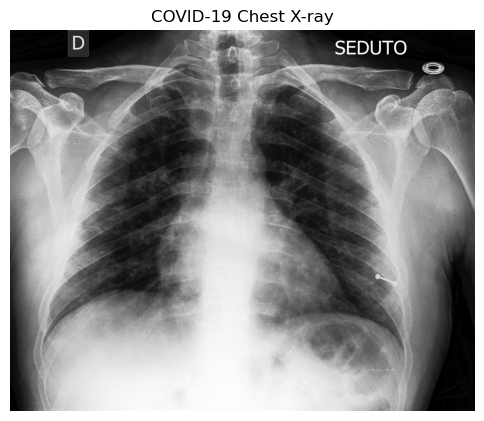

In [15]:
plt.figure(figsize=(6, 6))

plt.imshow(image, cmap="gray")
plt.title("COVID-19 Chest X-ray")
plt.axis("off")

plt.show()

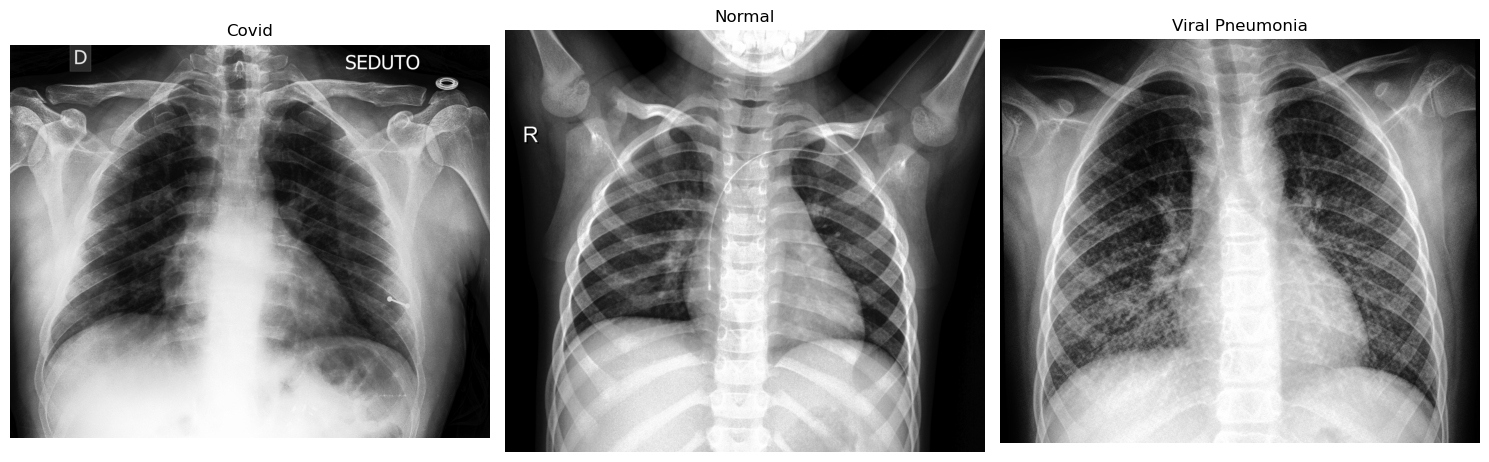

In [16]:
plt.figure(figsize=(15, 5))

for i, class_name in enumerate(classes):
    
    class_folder = os.path.join(train_path, class_name)
    image_files = os.listdir(class_folder)
    
    image_path = os.path.join(class_folder, image_files[0])
    image = Image.open(image_path)
    
    plt.subplot(1, 3, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

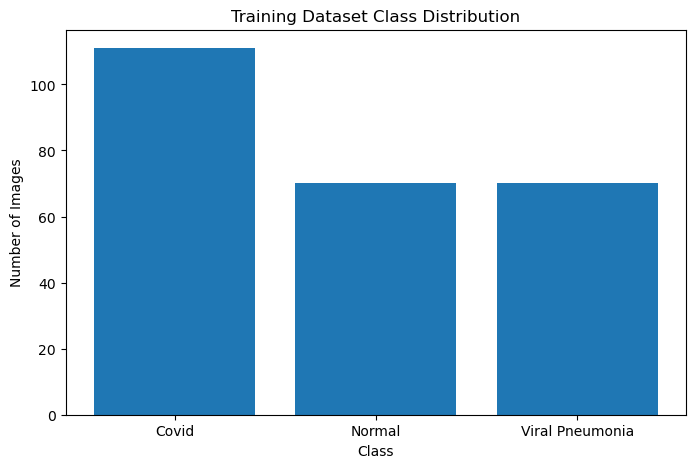

In [17]:
train_counts = []

for class_name in classes:
    class_folder = os.path.join(train_path, class_name)
    count = len(os.listdir(class_folder))
    train_counts.append(count)

plt.figure(figsize=(8, 5))

plt.bar(classes, train_counts)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

In [18]:
total_train_images = sum(train_counts)

for class_name, count in zip(classes, train_counts):
    percentage = (count / total_train_images) * 100
    
    print(
        f"{class_name}: {count} images "
        f"({percentage:.2f}%)"
    )

Covid: 111 images (44.22%)
Normal: 70 images (27.89%)
Viral Pneumonia: 70 images (27.89%)


In [20]:
IMG_SIZE = 128

In [21]:
!pip install opencv-python

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   - -------------------------------------- 1.3/44.0 MB 10.9 MB/s eta 0:00:04
   ---- ----------------------------------- 5.0/44.0 MB 15.5 MB/s eta 0:00:03
   ------- -------------------------------- 8.4/44.0 MB 15.9 MB/s eta 0:00:03
   ---------- ----------------------------- 12.1/44.0 MB 16.5 MB/s eta 0:00:02
   ------------- -------------------------- 14.9/44.0 MB 16.0 MB/s eta 0:00:02
   ---------------- ----------------------- 18.1/44.0 MB 15.7 MB/s eta 0:00:02
   ------------------- -------------------- 21.2/44.0 MB 15.8 MB/s eta 0:00:02
   ---------------------- ----------------- 24.9/44.0 MB 15.8 MB/s eta 0:00:02
   ------------------------- -------------- 28.3/44.0 MB 16.0 MB/s eta 0:00:01
   ----------------------------- ---------- 32.8/44.0 MB 16.5 MB/s eta 0:00:01
   -------------------------------- ------- 36.2/44.0 MB 16.5 MB/s eta 0:00:01
   ------------------------------------ --- 40.1/44.0 MB 16.7 MB

In [22]:
import cv2

In [23]:
IMG_SIZE = 128

class_names = ["Covid", "Normal", "Viral Pneumonia"]

label_map = {
    "Covid": 0,
    "Normal": 1,
    "Viral Pneumonia": 2
}

print("Image size:", IMG_SIZE)
print("Classes:", class_names)
print("Label mapping:", label_map)

Image size: 128
Classes: ['Covid', 'Normal', 'Viral Pneumonia']
Label mapping: {'Covid': 0, 'Normal': 1, 'Viral Pneumonia': 2}


In [24]:
def load_images_from_folder(folder_path):
    
    images = []
    labels = []
    
    for class_name in class_names:
        
        class_folder = os.path.join(folder_path, class_name)
        
        label = label_map[class_name]
        
        for image_file in os.listdir(class_folder):
            
            image_path = os.path.join(class_folder, image_file)
            
            image = cv2.imread(image_path)
            
            if image is None:
                continue
            
            image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
            
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            
            images.append(image)
            labels.append(label)
    
    return np.array(images), np.array(labels)

In [25]:
X_train, y_train = load_images_from_folder(train_path)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (251, 128, 128, 3)
y_train shape: (251,)


In [26]:
print("First 20 labels:")
print(y_train[:20])

First 20 labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [27]:
unique_labels, counts = np.unique(y_train, return_counts=True)

for label, count in zip(unique_labels, counts):
    print(class_names[label], ":", count)

Covid : 111
Normal : 70
Viral Pneumonia : 70


In [28]:
X_test, y_test = load_images_from_folder(test_path)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (66, 128, 128, 3)
y_test shape: (66,)


In [29]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [30]:
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


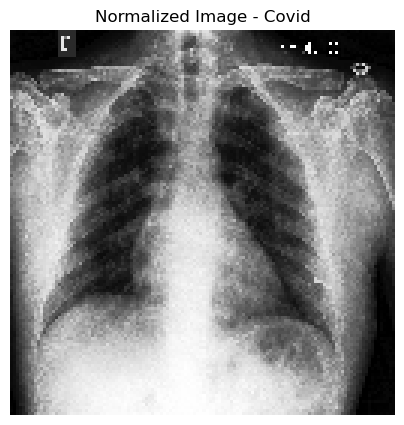

In [31]:
plt.figure(figsize=(5, 5))

plt.imshow(X_train[0])

plt.title(
    "Normalized Image - " +
    class_names[y_train[0]]
)

plt.axis("off")
plt.show()

In [32]:
print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])

print("Image shape:", X_train.shape[1:])

print("Number of training labels:", len(y_train))
print("Number of testing labels:", len(y_test))

Training images: 251
Testing images: 66
Image shape: (128, 128, 3)
Number of training labels: 251
Number of testing labels: 66


In [33]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

X_train shape: (251, 128, 128, 3)
y_train shape: (251,)
X_test shape: (66, 128, 128, 3)
y_test shape: (66,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [34]:
from sklearn.model_selection import train_test_split

In [35]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [36]:
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print()

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Test labels:", y_test.shape)

Training set: (200, 128, 128, 3)
Validation set: (51, 128, 128, 3)
Test set: (66, 128, 128, 3)

Training labels: (200,)
Validation labels: (51,)
Test labels: (66,)


In [37]:
print("Training distribution:")
unique, counts = np.unique(y_train, return_counts=True)

for label, count in zip(unique, counts):
    print(class_names[label], ":", count)

print()

print("Validation distribution:")
unique, counts = np.unique(y_val, return_counts=True)

for label, count in zip(unique, counts):
    print(class_names[label], ":", count)

print()

print("Test distribution:")
unique, counts = np.unique(y_test, return_counts=True)

for label, count in zip(unique, counts):
    print(class_names[label], ":", count)

Training distribution:
Covid : 88
Normal : 56
Viral Pneumonia : 56

Validation distribution:
Covid : 23
Normal : 14
Viral Pneumonia : 14

Test distribution:
Covid : 26
Normal : 20
Viral Pneumonia : 20


In [1]:
!pip install tensorflow


  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl (351.2 MB)


In [2]:
import tensorflow as tf
from tensorflow import keras

In [4]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

from tensorflow import keras

print("Keras is working!")

TensorFlow version: 2.21.0
Keras is working!


In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2

from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
dataset_path = "data/Covid19-dataset"

train_path = os.path.join(dataset_path, "train")
test_path = os.path.join(dataset_path, "test")

print("Training path:", train_path)
print("Testing path:", test_path)

Training path: data/Covid19-dataset\train
Testing path: data/Covid19-dataset\test


In [7]:
IMG_SIZE = 128

class_names = ["Covid", "Normal", "Viral Pneumonia"]

label_map = {
    "Covid": 0,
    "Normal": 1,
    "Viral Pneumonia": 2
}

print("Classes:", class_names)
print("Labels:", label_map)

Classes: ['Covid', 'Normal', 'Viral Pneumonia']
Labels: {'Covid': 0, 'Normal': 1, 'Viral Pneumonia': 2}


In [8]:
def load_images_from_folder(folder_path):
    
    images = []
    labels = []
    
    for class_name in class_names:
        
        class_folder = os.path.join(folder_path, class_name)
        
        label = label_map[class_name]
        
        for image_file in os.listdir(class_folder):
            
            image_path = os.path.join(class_folder, image_file)
            
            image = cv2.imread(image_path)
            
            if image is None:
                continue
            
            image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
            
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            
            images.append(image)
            labels.append(label)
    
    return np.array(images), np.array(labels)

In [9]:
X_train, y_train = load_images_from_folder(train_path)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (251, 128, 128, 3)
y_train shape: (251,)


In [10]:
X_test, y_test = load_images_from_folder(test_path)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (66, 128, 128, 3)
y_test shape: (66,)


In [11]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

Minimum: 0.0
Maximum: 1.0


In [12]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [13]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (200, 128, 128, 3) (200,)
Validation: (51, 128, 128, 3) (51,)
Test: (66, 128, 128, 3) (66,)


In [14]:
num_classes = 3

y_train_encoded = keras.utils.to_categorical(
    y_train,
    num_classes=num_classes
)

y_val_encoded = keras.utils.to_categorical(
    y_val,
    num_classes=num_classes
)

y_test_encoded = keras.utils.to_categorical(
    y_test,
    num_classes=num_classes
)

In [15]:
print("Original labels:")
print(y_train[:10])

print()

print("One-hot encoded labels:")
print(y_train_encoded[:10])

Original labels:
[0 0 1 0 0 0 2 0 0 2]

One-hot encoded labels:
[[1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 0. 1.]]


In [16]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Encoded training labels:", y_train_encoded.shape)

Training: (200, 128, 128, 3) (200,)
Validation: (51, 128, 128, 3) (51,)
Test: (66, 128, 128, 3) (66,)
Encoded training labels: (200, 3)


In [17]:
from tensorflow.keras import layers, models

basic_cnn = models.Sequential([
    
    
    layers.Input(shape=(128, 128, 3)),
    
 
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
 
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
   
    layers.Flatten(),
    

    layers.Dense(128, activation='relu'),
    
   
    layers.Dropout(0.5),
    
  
    layers.Dense(3, activation='softmax')
])

print("Basic CNN created successfully!")

Basic CNN created successfully!


In [18]:
basic_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 57600)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       7,372,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,392,707 (28.20 MB)

 Trainable params: 7,392,707 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
basic_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [20]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_basic = basic_cnn.fit(
    X_train,
    y_train_encoded,
    validation_data=(X_val, y_val_encoded),
    epochs=30,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 249ms/step - accuracy: 0.5050 - loss: 1.9181 - val_accuracy: 0.7843 - val_loss: 0.8514
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 206ms/step - accuracy: 0.7900 - loss: 0.5710 - val_accuracy: 0.8235 - val_loss: 0.5112
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 186ms/step - accuracy: 0.8600 - loss: 0.3736 - val_accuracy: 0.8627 - val_loss: 0.3003
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 194ms/step - accuracy: 0.9450 - loss: 0.2193 - val_accuracy: 0.8627 - val_loss: 0.2518
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 199ms/step - accuracy: 0.9250 - loss: 0.1948 - val_accuracy: 0.9020 - val_loss: 0.2096
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 208ms/step - accuracy: 0.9650 - loss: 0.1342 - val_accuracy: 0.9216 - val_loss: 0.1930
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 211ms/step - accuracy: 0.9800 - loss: 0.0706 - val_accuracy: 0.9020 - val_loss: 0.2029
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 207ms/step - accuracy: 0.9700 - loss: 0.0853 - val_accuracy: 0.

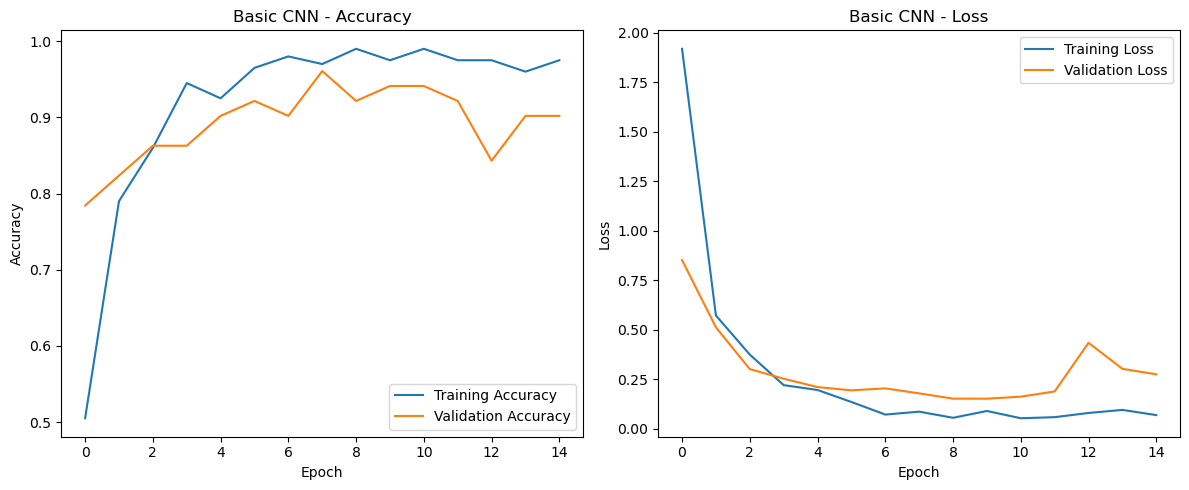

In [21]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_basic.history['accuracy'], label='Training Accuracy')
plt.plot(history_basic.history['val_accuracy'], label='Validation Accuracy')
plt.title('Basic CNN - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_basic.history['loss'], label='Training Loss')
plt.plot(history_basic.history['val_loss'], label='Validation Loss')
plt.title('Basic CNN - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [22]:
test_loss, test_accuracy = basic_cnn.evaluate(
    X_test,
    y_test_encoded,
    verbose=1
)

print("Basic CNN Test Loss:", test_loss)
print("Basic CNN Test Accuracy:", test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.8788 - loss: 0.2263 
Basic CNN Test Loss: 0.22633640468120575
Basic CNN Test Accuracy: 0.8787878751754761


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step 
Confusion Matrix:
[[26  0  0]
 [ 0 18  2]
 [ 0  6 14]]


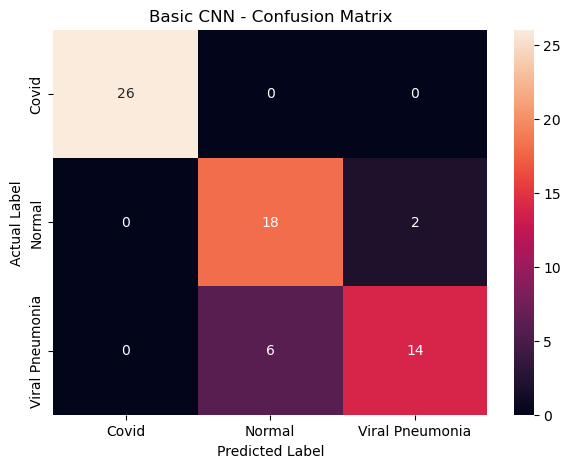

In [23]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns


y_pred_prob = basic_cnn.predict(X_test)


y_pred = np.argmax(y_pred_prob, axis=1)


cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)


plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Basic CNN - Confusion Matrix")
plt.show()

In [24]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names
    )
)

Classification Report:

                 precision    recall  f1-score   support

          Covid       1.00      1.00      1.00        26
         Normal       0.75      0.90      0.82        20
Viral Pneumonia       0.88      0.70      0.78        20

       accuracy                           0.88        66
      macro avg       0.88      0.87      0.87        66
   weighted avg       0.89      0.88      0.88        66



In [25]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score


y_test_binary = label_binarize(y_test, classes=[0, 1, 2])


roc_auc = roc_auc_score(
    y_test_binary,
    y_pred_prob,
    multi_class='ovr'
)

print("Basic CNN ROC-AUC:", roc_auc)

Basic CNN ROC-AUC: 0.9811594202898549


In [26]:
deep_cnn = models.Sequential([
    
    layers.Input(shape=(128, 128, 3)),
    
    
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    
    
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    
    
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    
    
    layers.Dense(3, activation='softmax')
])

deep_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 128, 128, 32)        │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 64, 64, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 32768)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       4,194,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,334,243 (16.53 MB)

 Trainable params: 4,334,243 (16.53 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
deep_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Deep CNN compiled successfully!")

Deep CNN compiled successfully!


In [28]:
early_stopping_deep = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [29]:
history_deep = deep_cnn.fit(
    X_train,
    y_train_encoded,
    validation_data=(X_val, y_val_encoded),
    epochs=30,
    batch_size=16,
    callbacks=[early_stopping_deep],
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 367ms/step - accuracy: 0.4750 - loss: 1.1621 - val_accuracy: 0.5882 - val_loss: 0.9369
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 310ms/step - accuracy: 0.7450 - loss: 0.6658 - val_accuracy: 0.8039 - val_loss: 0.3588
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 321ms/step - accuracy: 0.8600 - loss: 0.4809 - val_accuracy: 0.8824 - val_loss: 0.3157
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 311ms/step - accuracy: 0.8700 - loss: 0.3455 - val_accuracy: 0.9020 - val_loss: 0.3204
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 334ms/step - accuracy: 0.8300 - loss: 0.3276 - val_accuracy: 0.8431 - val_loss: 0.3323
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 322ms/step - accuracy: 0.9200 - loss: 0.2322 - val_accuracy: 0.8824 - val_loss: 0.2787
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 305ms/step - accuracy: 0.9150 - loss: 0.1936 - val_accuracy: 0.9020 - val_loss: 0.3156
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 306ms/step - accuracy: 0.9100 - loss: 0.1904 - val_accuracy: 0.

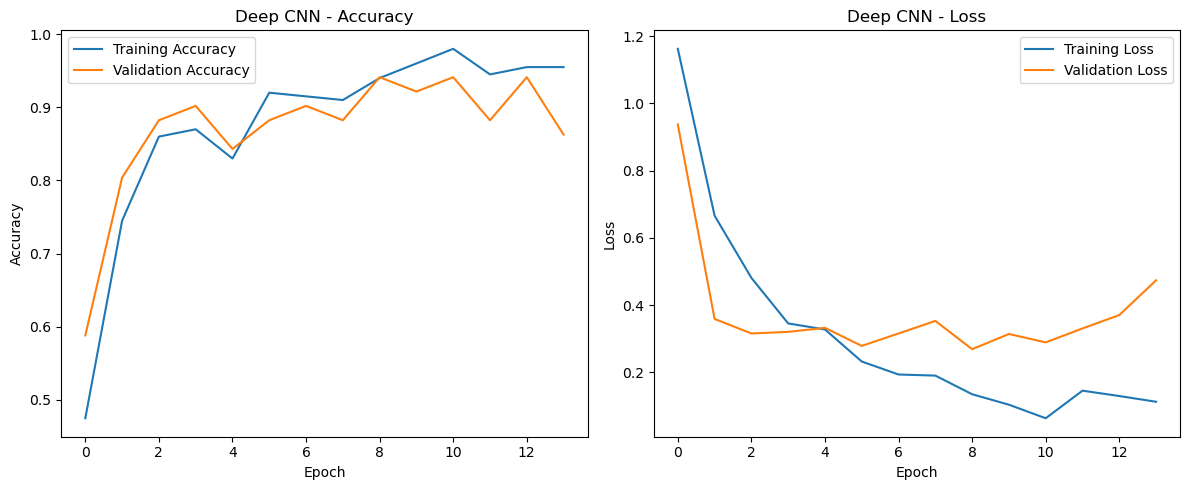

In [30]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_deep.history['accuracy'], label='Training Accuracy')
plt.plot(history_deep.history['val_accuracy'], label='Validation Accuracy')
plt.title('Deep CNN - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_deep.history['loss'], label='Training Loss')
plt.plot(history_deep.history['val_loss'], label='Validation Loss')
plt.title('Deep CNN - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [31]:
deep_test_loss, deep_test_accuracy = deep_cnn.evaluate(
    X_test,
    y_test_encoded,
    verbose=1
)

print("Deep CNN Test Loss:", deep_test_loss)
print("Deep CNN Test Accuracy:", deep_test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.8333 - loss: 0.7359
Deep CNN Test Loss: 0.7359367609024048
Deep CNN Test Accuracy: 0.8333333134651184


In [32]:
deep_pred_prob = deep_cnn.predict(X_test)
deep_pred = np.argmax(deep_pred_prob, axis=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 129ms/step


Deep CNN Confusion Matrix:
[[23  1  2]
 [ 0 20  0]
 [ 3  5 12]]


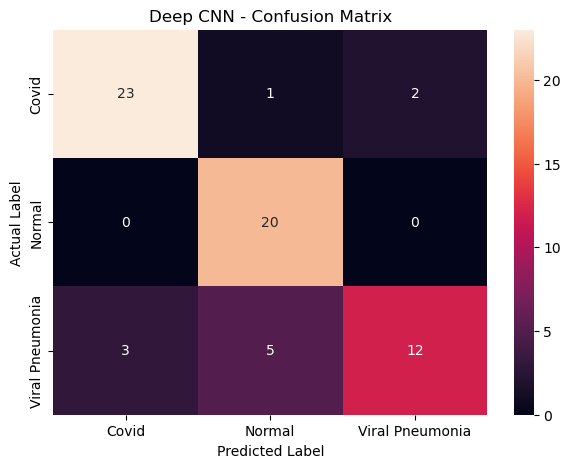

In [33]:
deep_cm = confusion_matrix(y_test, deep_pred)

print("Deep CNN Confusion Matrix:")
print(deep_cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    deep_cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Deep CNN - Confusion Matrix")
plt.show()

In [34]:
print("Deep CNN Classification Report:\n")

print(
    classification_report(
        y_test,
        deep_pred,
        target_names=class_names
    )
)

Deep CNN Classification Report:

                 precision    recall  f1-score   support

          Covid       0.88      0.88      0.88        26
         Normal       0.77      1.00      0.87        20
Viral Pneumonia       0.86      0.60      0.71        20

       accuracy                           0.83        66
      macro avg       0.84      0.83      0.82        66
   weighted avg       0.84      0.83      0.83        66



In [35]:
deep_roc_auc = roc_auc_score(
    y_test_binary,
    deep_pred_prob,
    multi_class='ovr'
)

print("Deep CNN ROC-AUC:", deep_roc_auc)

Deep CNN ROC-AUC: 0.9421265328874023


In [36]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

In [37]:
vgg_base = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)

print("VGG16 loaded successfully!")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step 
VGG16 loaded successfully!


In [38]:
vgg_base.trainable = False

In [39]:
vgg_model = models.Sequential([
    
    layers.Input(shape=(128, 128, 3)),
    
   
    layers.Lambda(
        lambda x: preprocess_input(x * 255.0)
    ),
    
  
    vgg_base,
    
  
    layers.GlobalAveragePooling2D(),
    
 
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    

    layers.Dense(3, activation='softmax')
])

vgg_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                      │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 4, 4, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,780,739 (56.38 MB)

 Trainable params: 66,051 (258.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [41]:
vgg_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("VGG16 model compiled successfully!")

VGG16 model compiled successfully!


In [42]:
early_stopping_vgg = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [43]:
history_vgg = vgg_model.fit(
    X_train,
    y_train_encoded,
    validation_data=(X_val, y_val_encoded),
    epochs=30,
    batch_size=16,
    callbacks=[early_stopping_vgg],
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.3750 - loss: 8.7387 - val_accuracy: 0.3529 - val_loss: 3.6579
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.4600 - loss: 6.0748 - val_accuracy: 0.5098 - val_loss: 2.6021
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.4550 - loss: 5.7604 - val_accuracy: 0.6667 - val_loss: 1.8213
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.5600 - loss: 4.6676 - val_accuracy: 0.7059 - val_loss: 1.4289
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.5650 - loss: 4.0439 - val_accuracy: 0.7647 - val_loss: 1.1425
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.6000 - loss: 3.0619 - val_accuracy: 0.7843 - val_loss: 1.0169
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.6300 - loss: 2.8711 - val_accuracy: 0.8039 - val_loss: 0.8070
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 962ms/step - accuracy: 0.7350 - loss: 1.9226 - val_accuracy: 0.8627 - val_lo

In [44]:
vgg_test_loss, vgg_test_accuracy = vgg_model.evaluate(
    X_test,
    y_test_encoded,
    verbose=1
)

print("VGG16 Test Loss:", vgg_test_loss)
print("VGG16 Test Accuracy:", vgg_test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 864ms/step - accuracy: 0.8182 - loss: 0.8517
VGG16 Test Loss: 0.8516594767570496
VGG16 Test Accuracy: 0.8181818127632141


In [45]:
vgg_pred_prob = vgg_model.predict(X_test)
vgg_pred = np.argmax(vgg_pred_prob, axis=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 885ms/step


In [46]:
print("VGG16 Classification Report:\n")

print(
    classification_report(
        y_test,
        vgg_pred,
        target_names=class_names
    )
)

VGG16 Classification Report:

                 precision    recall  f1-score   support

          Covid       1.00      0.85      0.92        26
         Normal       0.78      0.70      0.74        20
Viral Pneumonia       0.69      0.90      0.78        20

       accuracy                           0.82        66
      macro avg       0.82      0.82      0.81        66
   weighted avg       0.84      0.82      0.82        66



In [47]:
vgg_roc_auc = roc_auc_score(
    y_test_binary,
    vgg_pred_prob,
    multi_class='ovr'
)

print("VGG16 ROC-AUC:", vgg_roc_auc)

VGG16 ROC-AUC: 0.9493589743589744


In [48]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

In [49]:
resnet_base = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)

resnet_base.trainable = False

print("ResNet50 loaded successfully!")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step 
ResNet50 loaded successfully!


In [50]:
resnet_model = models.Sequential([
    
    layers.Input(shape=(128, 128, 3)),
    
    # ResNet50-specific preprocessing
    layers.Lambda(
        lambda x: resnet_preprocess(x * 255.0)
    ),
    
    # Pretrained ResNet50
    resnet_base,
    
    layers.GlobalAveragePooling2D(),
    
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    
    layers.Dense(3, activation='softmax')
])

resnet_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lambda_1 (Lambda)                    │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resnet50 (Functional)                │ (None, 4, 4, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │         262,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [51]:
resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("ResNet50 compiled successfully!")

ResNet50 compiled successfully!


In [52]:
early_stopping_resnet = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [53]:
history_resnet = resnet_model.fit(
    X_train,
    y_train_encoded,
    validation_data=(X_val, y_val_encoded),
    epochs=30,
    batch_size=16,
    callbacks=[early_stopping_resnet],
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 715ms/step - accuracy: 0.4100 - loss: 1.9434 - val_accuracy: 0.7059 - val_loss: 0.6635
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 443ms/step - accuracy: 0.6550 - loss: 0.9714 - val_accuracy: 0.9412 - val_loss: 0.3754
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 550ms/step - accuracy: 0.7400 - loss: 0.6045 - val_accuracy: 0.9216 - val_loss: 0.3007
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 447ms/step - accuracy: 0.8450 - loss: 0.4490 - val_accuracy: 0.9216 - val_loss: 0.3001
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 408ms/step - accuracy: 0.8550 - loss: 0.3320 - val_accuracy: 0.9216 - val_loss: 0.2852
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 410ms/step - accuracy: 0.9200 - loss: 0.2744 - val_accuracy: 0.9216 - val_loss: 0.2813
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 410ms/step - accuracy: 0.8950 - loss: 0.2670 - val_accuracy: 0.9216 - val_loss: 0.2998
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 398ms/step - accuracy: 0.9000 - loss: 0.2787 - val_accuracy: 

In [54]:
resnet_test_loss, resnet_test_accuracy = resnet_model.evaluate(
    X_test,
    y_test_encoded,
    verbose=1
)

print("ResNet50 Test Loss:", resnet_test_loss)
print("ResNet50 Test Accuracy:", resnet_test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 355ms/step - accuracy: 0.7727 - loss: 0.4504
ResNet50 Test Loss: 0.45040667057037354
ResNet50 Test Accuracy: 0.7727272510528564


In [55]:
resnet_pred_prob = resnet_model.predict(X_test)
resnet_pred = np.argmax(resnet_pred_prob, axis=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step   


ResNet50 Confusion Matrix:
[[23  0  3]
 [ 1 10  9]
 [ 1  1 18]]


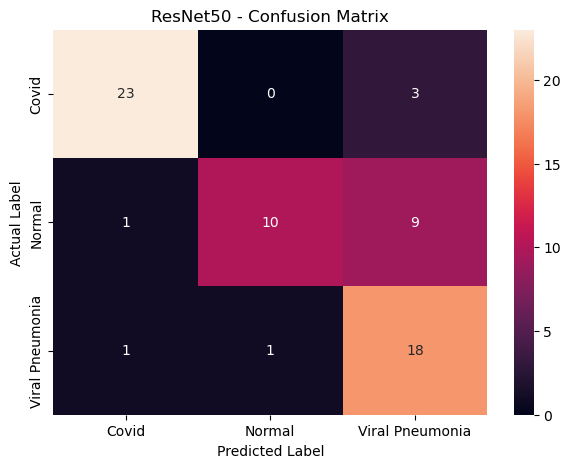

In [56]:
resnet_cm = confusion_matrix(y_test, resnet_pred)

print("ResNet50 Confusion Matrix:")
print(resnet_cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    resnet_cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ResNet50 - Confusion Matrix")
plt.show()

In [57]:
print("ResNet50 Classification Report:\n")

print(
    classification_report(
        y_test,
        resnet_pred,
        target_names=class_names
    )
)

ResNet50 Classification Report:

                 precision    recall  f1-score   support

          Covid       0.92      0.88      0.90        26
         Normal       0.91      0.50      0.65        20
Viral Pneumonia       0.60      0.90      0.72        20

       accuracy                           0.77        66
      macro avg       0.81      0.76      0.76        66
   weighted avg       0.82      0.77      0.77        66



In [58]:
resnet_roc_auc = roc_auc_score(
    y_test_binary,
    resnet_pred_prob,
    multi_class='ovr'
)

print("ResNet50 ROC-AUC:", resnet_roc_auc)

ResNet50 ROC-AUC: 0.9523132664437012


In [59]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:")
print(class_weights)

Class Weights:
{np.int64(0): np.float64(0.7575757575757576), np.int64(1): np.float64(1.1904761904761905), np.int64(2): np.float64(1.1904761904761905)}


In [60]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

datagen.fit(X_train)

print("Data augmentation generator created successfully!")

Data augmentation generator created successfully!


In [61]:
vgg_aug_base = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)

vgg_aug_base.trainable = False

In [62]:
vgg_aug_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Lambda(
        lambda x: preprocess_input(x * 255.0)
    ),

    vgg_aug_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(3, activation='softmax')
])

vgg_aug_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Augmented VGG16 created successfully!")

Augmented VGG16 created successfully!


In [63]:
early_stopping_aug = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [64]:
history_vgg_aug = vgg_aug_model.fit(
    datagen.flow(
        X_train,
        y_train_encoded,
        batch_size=16,
        shuffle=True
    ),
    validation_data=(X_val, y_val_encoded),
    epochs=30,
    class_weight=class_weights,
    callbacks=[early_stopping_aug],
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.3500 - loss: 8.7191 - val_accuracy: 0.4118 - val_loss: 5.8625
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.4450 - loss: 6.6159 - val_accuracy: 0.4902 - val_loss: 3.4282
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.4700 - loss: 6.1636 - val_accuracy: 0.4902 - val_loss: 2.2583
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.4950 - loss: 4.2562 - val_accuracy: 0.6667 - val_loss: 1.6550
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.5750 - loss: 4.7035 - val_accuracy: 0.6863 - val_loss: 1.4330
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.5950 - loss: 4.3197 - val_accuracy: 0.7451 - val_loss: 1.3757
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.5950 - loss: 4.3646 - val_accuracy: 0.7843 - val_loss: 1.2857
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.6500 - loss: 3.5701 - val_accuracy: 0.8039 - val_loss:

In [65]:
vgg_aug_test_loss, vgg_aug_test_accuracy = vgg_aug_model.evaluate(
    X_test,
    y_test_encoded,
    verbose=1
)

print("Augmented VGG16 Test Loss:", vgg_aug_test_loss)
print("Augmented VGG16 Test Accuracy:", vgg_aug_test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 904ms/step - accuracy: 0.7576 - loss: 1.1421
Augmented VGG16 Test Loss: 1.1420502662658691
Augmented VGG16 Test Accuracy: 0.7575757503509521


In [66]:
vgg_aug_pred_prob = vgg_aug_model.predict(X_test)
vgg_aug_pred = np.argmax(vgg_aug_pred_prob, axis=1)

print("Augmented VGG16 Classification Report:\n")

print(
    classification_report(
        y_test,
        vgg_aug_pred,
        target_names=class_names
    )
)

vgg_aug_roc_auc = roc_auc_score(
    y_test_binary,
    vgg_aug_pred_prob,
    multi_class='ovr'
)

print("Augmented VGG16 ROC-AUC:", vgg_aug_roc_auc)

3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step
Augmented VGG16 Classification Report:

                 precision    recall  f1-score   support

          Covid       1.00      0.81      0.89        26
         Normal       0.61      0.70      0.65        20
Viral Pneumonia       0.68      0.75      0.71        20

       accuracy                           0.76        66
      macro avg       0.76      0.75      0.75        66
   weighted avg       0.79      0.76      0.77        66

Augmented VGG16 ROC-AUC: 0.9134057971014493


In [67]:
vgg_aug_base.trainable = True

# Freeze most layers and train only the last 4 layers
for layer in vgg_aug_base.layers[:-4]:
    layer.trainable = False

print("Total VGG16 layers:", len(vgg_aug_base.layers))
print(
    "Trainable VGG16 layers:",
    sum(layer.trainable for layer in vgg_aug_base.layers)
)

Total VGG16 layers: 19
Trainable VGG16 layers: 4


In [68]:
vgg_aug_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("VGG16 ready for fine-tuning!")

VGG16 ready for fine-tuning!


In [69]:
early_stopping_fine = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [70]:
history_vgg_fine = vgg_aug_model.fit(
    datagen.flow(
        X_train,
        y_train_encoded,
        batch_size=16,
        shuffle=True
    ),
    validation_data=(X_val, y_val_encoded),
    epochs=20,
    class_weight=class_weights,
    callbacks=[early_stopping_fine],
    verbose=1
)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.8350 - loss: 1.1687 - val_accuracy: 0.8431 - val_loss: 0.9766
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.8400 - loss: 0.9055 - val_accuracy: 0.8824 - val_loss: 0.7424
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.8650 - loss: 0.9453 - val_accuracy: 0.8824 - val_loss: 0.7547
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.9050 - loss: 0.5743 - val_accuracy: 0.8824 - val_loss: 0.8192
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.8750 - loss: 0.6733 - val_accuracy: 0.8824 - val_loss: 0.8084
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.8700 - loss: 0.5014 - val_accuracy: 0.8824 - val_loss: 0.7401
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.9350 - loss: 0.3561 - val_accuracy: 0.8824 - val_loss: 0.7275
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.8750 - loss: 0.5383 - val_accuracy: 0.9020 - val_loss:

In [71]:
vgg_fine_test_loss, vgg_fine_test_accuracy = vgg_aug_model.evaluate(
    X_test,
    y_test_encoded,
    verbose=1
)

print("Fine-Tuned VGG16 Test Loss:", vgg_fine_test_loss)
print("Fine-Tuned VGG16 Test Accuracy:", vgg_fine_test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 861ms/step - accuracy: 0.8939 - loss: 0.5145
Fine-Tuned VGG16 Test Loss: 0.5145218968391418
Fine-Tuned VGG16 Test Accuracy: 0.8939393758773804


In [72]:
vgg_fine_pred_prob = vgg_aug_model.predict(X_test)

vgg_fine_pred = np.argmax(
    vgg_fine_pred_prob,
    axis=1
)

3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step   


In [73]:
print("Fine-Tuned VGG16 Classification Report:\n")

print(
    classification_report(
        y_test,
        vgg_fine_pred,
        target_names=class_names
    )
)

Fine-Tuned VGG16 Classification Report:

                 precision    recall  f1-score   support

          Covid       1.00      1.00      1.00        26
         Normal       0.78      0.90      0.84        20
Viral Pneumonia       0.88      0.75      0.81        20

       accuracy                           0.89        66
      macro avg       0.89      0.88      0.88        66
   weighted avg       0.90      0.89      0.89        66



In [74]:
vgg_fine_roc_auc = roc_auc_score(
    y_test_binary,
    vgg_fine_pred_prob,
    multi_class='ovr'
)

print("Fine-Tuned VGG16 ROC-AUC:", vgg_fine_roc_auc)

Fine-Tuned VGG16 ROC-AUC: 0.9619565217391304


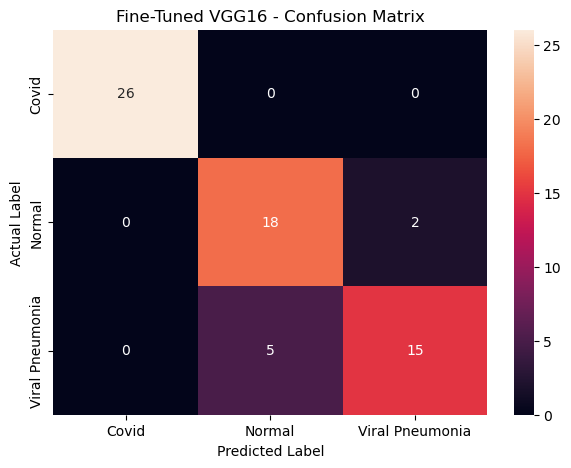

In [75]:
vgg_fine_cm = confusion_matrix(
    y_test,
    vgg_fine_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    vgg_fine_cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Fine-Tuned VGG16 - Confusion Matrix")
plt.show()

In [76]:
!pip install keras-tuner


   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   ---------------------------------------- 2/2 [keras-tuner]



In [77]:
import keras_tuner as kt

print("Keras Tuner imported successfully!")

Keras Tuner imported successfully!


In [78]:
def build_tuned_model(hp):

    model = models.Sequential()

    model.add(layers.Input(shape=(128, 128, 3)))

    # First convolution layer
    model.add(
        layers.Conv2D(
            filters=hp.Choice('conv1_filters', [16, 32, 64]),
            kernel_size=(3, 3),
            activation='relu'
        )
    )

    model.add(layers.MaxPooling2D((2, 2)))

    # Second convolution layer
    model.add(
        layers.Conv2D(
            filters=hp.Choice('conv2_filters', [32, 64, 128]),
            kernel_size=(3, 3),
            activation='relu'
        )
    )

    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())

    model.add(
        layers.Dense(
            units=hp.Choice('dense_units', [64, 128, 256]),
            activation='relu'
        )
    )

    model.add(
        layers.Dropout(
            hp.Choice('dropout', [0.3, 0.5])
        )
    )

    model.add(layers.Dense(3, activation='softmax'))

    learning_rate = hp.Choice(
        'learning_rate',
        [0.001, 0.0001]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [79]:
tuner = kt.RandomSearch(
    build_tuned_model,
    objective='val_accuracy',
    max_trials=5,
    executions_per_trial=1,
    directory='keras_tuner_results',
    project_name='covid_cnn_tuning',
    overwrite=True
)

print("Keras Tuner created successfully!")

Keras Tuner created successfully!


In [81]:
%pip install tensorboard


   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   --- ------------------------------------ 0.5/5.5 MB 4.8 MB/s eta 0:00:02
   ---------------------------- ----------- 3.9/5.5 MB 14.0 MB/s eta 0:00:01
   ---------------------------------------- 5.5/5.5 MB 13.9 MB/s eta 0:00:00

   -------------------- ------------------- 1/2 [tensorboard]
   -------------------- ------------------- 1/2 [tensorboard]
   -------------------- ------------------- 1/2 [tensorboard]
   -------------------- ------------------- 1/2 [tensorboard]
   -------------------- ------------------- 1/2 [tensorboard]
   -------------------- ------------------- 1/2 [tensorboard]
   -------------------- ------------------- 1/2 [tensorboard]
   -------------------- ------------------- 1/2 [tensorboard]
   -------------------- ------------------- 1/2 [tensorboard]
   ---------------------------------------- 2/2 [tensorboard]



In [82]:
import tensorflow as tf
import tensorboard
import keras_tuner as kt

print("TensorFlow:", tf.__version__)
print("TensorBoard:", tensorboard.__version__)
print("Keras Tuner is working!")

TensorFlow: 2.21.0
TensorBoard: 2.21.0
Keras Tuner is working!


In [83]:
tuner = kt.RandomSearch(
    build_tuned_model,
    objective='val_accuracy',
    max_trials=5,
    executions_per_trial=1,
    directory='keras_tuner_results',
    project_name='covid_cnn_tuning',
    overwrite=True
)

print("Fresh Keras Tuner created successfully!")

Fresh Keras Tuner created successfully!


In [84]:
overwrite=True

In [85]:
tuner.search(
    X_train,
    y_train_encoded,
    validation_data=(X_val, y_val_encoded),
    epochs=10,
    batch_size=16,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Trial 5 Complete [00h 00m 10s]
val_accuracy: 0.9607843160629272

Best val_accuracy So Far: 0.9607843160629272
Total elapsed time: 00h 03m 06s


In [86]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best Conv1 Filters:", best_hps.get('conv1_filters'))
print("Best Conv2 Filters:", best_hps.get('conv2_filters'))
print("Best Dense Units:", best_hps.get('dense_units'))
print("Best Dropout:", best_hps.get('dropout'))
print("Best Learning Rate:", best_hps.get('learning_rate'))

Best Conv1 Filters: 32
Best Conv2 Filters: 128
Best Dense Units: 128
Best Dropout: 0.3
Best Learning Rate: 0.001


In [87]:
tuned_cnn = tuner.hypermodel.build(best_hps)

tuned_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 61, 61, 128)         │          36,992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 30, 30, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 115200)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │      14,745,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,784,003 (56.40 MB)

 Trainable params: 14,784,003 (56.40 MB)

 Non-trainable params: 0 (0.00 B)

In [88]:
early_stopping_tuned = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_tuned = tuned_cnn.fit(
    X_train,
    y_train_encoded,
    validation_data=(X_val, y_val_encoded),
    epochs=30,
    batch_size=16,
    callbacks=[early_stopping_tuned],
    verbose=1
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 281ms/step - accuracy: 0.5000 - loss: 1.8456 - val_accuracy: 0.8431 - val_loss: 0.7231
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 301ms/step - accuracy: 0.8200 - loss: 0.4706 - val_accuracy: 0.9020 - val_loss: 0.2566
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 256ms/step - accuracy: 0.9200 - loss: 0.1889 - val_accuracy: 0.9412 - val_loss: 0.2708
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 291ms/step - accuracy: 0.9300 - loss: 0.2301 - val_accuracy: 0.9216 - val_loss: 0.2136
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 263ms/step - accuracy: 0.9350 - loss: 0.2199 - val_accuracy: 0.9020 - val_loss: 0.2730
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 246ms/step - accuracy: 0.9800 - loss: 0.1021 - val_accuracy: 0.8431 - val_loss: 0.4183
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 226ms/step - accuracy: 0.9850 - loss: 0.0665 - val_accuracy: 0.9216 - val_loss: 0.1831
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 237ms/step - accuracy: 0.9950 - loss: 0.0323 - val_accuracy: 0.

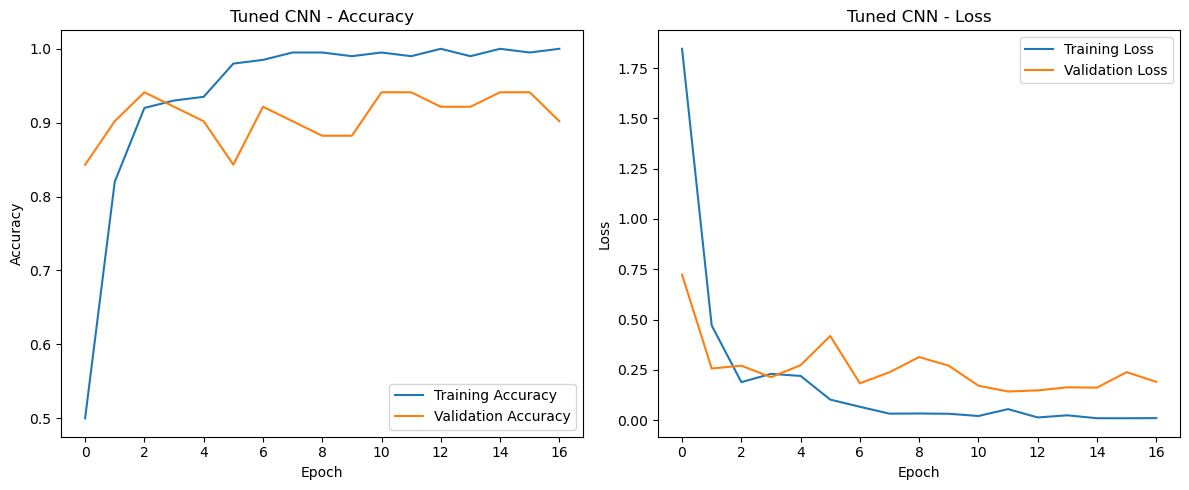

In [89]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_tuned.history['accuracy'], label='Training Accuracy')
plt.plot(history_tuned.history['val_accuracy'], label='Validation Accuracy')
plt.title('Tuned CNN - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_tuned.history['loss'], label='Training Loss')
plt.plot(history_tuned.history['val_loss'], label='Validation Loss')
plt.title('Tuned CNN - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [90]:
tuned_test_loss, tuned_test_accuracy = tuned_cnn.evaluate(
    X_test,
    y_test_encoded,
    verbose=1
)

print("Tuned CNN Test Loss:", tuned_test_loss)
print("Tuned CNN Test Accuracy:", tuned_test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.8788 - loss: 0.2099 
Tuned CNN Test Loss: 0.20987406373023987
Tuned CNN Test Accuracy: 0.8787878751754761


In [91]:

tuned_pred_prob = tuned_cnn.predict(X_test)
tuned_pred = np.argmax(tuned_pred_prob, axis=1)


print("Tuned CNN Classification Report:\n")

print(
    classification_report(
        y_test,
        tuned_pred,
        target_names=class_names
    )
)


tuned_roc_auc = roc_auc_score(
    y_test_binary,
    tuned_pred_prob,
    multi_class='ovr'
)

print("Tuned CNN ROC-AUC:", tuned_roc_auc)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step 
Tuned CNN Classification Report:

                 precision    recall  f1-score   support

          Covid       1.00      1.00      1.00        26
         Normal       0.77      0.85      0.81        20
Viral Pneumonia       0.83      0.75      0.79        20

       accuracy                           0.88        66
      macro avg       0.87      0.87      0.87        66
   weighted avg       0.88      0.88      0.88        66

Tuned CNN ROC-AUC: 0.9807971014492755


Fine-Tuned VGG16 is the final model, because it has the highest test accuracy (89.39%) and highest weighted F1 (0.89). The Basic CNN has the highest ROC-AUC

In [92]:
vgg_aug_model

<Sequential name=sequential_4, built=True>

In [93]:
vgg_aug_model.save("best_covid_model.keras")

print("Best model saved successfully!")

Best model saved successfully!


In [94]:
import os

print("My current Jupyter folder is:")
print(os.getcwd())

My current Jupyter folder is:
C:\Users\HP


In [96]:
print("Model exists:", os.path.exists("best_covid_model.keras"))

if os.path.exists("best_covid_model.keras"):
    print("Model location:")
    print(os.path.abspath("best_covid_model.keras"))

Model exists: True
Model location:
C:\Users\HP\best_covid_model.keras


In [97]:
print(os.getcwd())

C:\Users\HP


In [98]:
vgg_aug_model.save("best_covid_model.keras")

In [99]:
import os

print("Current folder:", os.getcwd())

print("\nModel exists:",
      os.path.exists("best_covid_model.keras"))

print("Dataset exists:",
      os.path.exists("data/Covid19-dataset"))

print("\nModel full location:")
print(os.path.abspath("best_covid_model.keras"))

Current folder: C:\Users\HP

Model exists: True
Dataset exists: True

Model full location:
C:\Users\HP\best_covid_model.keras


In [101]:
import os

print("Jupyter notebooks found:\n")

for file in os.listdir(r"C:\Users\HP"):
    if file.endswith(".ipynb"):
        print(file)

Jupyter notebooks found:

Himani DV.ipynb
Himani EDA .ipynb
Himani EDA Assignment .ipynb
Himani linear and Logistic Regression.ipynb
Himani Maths and Descriptive Stats Assignment.ipynb
Himani Stats Assignment.ipynb
Himani Verma EDA Mini Project.ipynb
Himani Verma Image Classification Using CNN Mini Project.ipynb
Himani Verma NLP, RNN Assignment.ipynb
Himani Verma Supervised Machine Learning Assignment.ipynb
Himani Verma Supervised ML Classification Mini Project.ipynb
Himani Verma Supervised ML Mini Project.ipynb
Himani Verma Unsupervised Machine Learning Assignment.ipynb
Mobile_Price_Prediction.ipynb
Supervised ML Decision Tree.ipynb
Untitled.ipynb
Untitled1.ipynb
Untitled2.ipynb
Untitled3.ipynb


In [103]:
import os
import shutil

project_folder = r"C:\Users\HP\COVID_Xray_CNN_Project"


os.makedirs(project_folder, exist_ok=True)


shutil.copy2(
    r"C:\Users\HP\Himani Verma Image Classification Using CNN Mini Project.ipynb",
    project_folder
)


shutil.copy2(
    r"C:\Users\HP\best_covid_model.keras",
    project_folder
)

print("Project folder created successfully!")
print("Location:", project_folder)

print("\nFiles currently inside:")
for item in os.listdir(project_folder):
    print(item)

Project folder created successfully!
Location: C:\Users\HP\COVID_Xray_CNN_Project

Files currently inside:
best_covid_model.keras
Himani Verma Image Classification Using CNN Mini Project.ipynb


In [ ]:
import tensorflow as tf

model_path = r"C:\Users\HP\COVID_Xray_CNN_Project\best_covid_model.keras"

loaded_model = tf.keras.models.load_model(
    model_path,
    safe_mode=False
)

print("Model loaded successfully!")
print("Input shape:", loaded_model.input_shape)
print("Output shape:", loaded_model.output_shape)

In [ ]:
import numpy as np


dummy_image = np.zeros((1, 128, 128, 3), dtype=np.float32)


dummy_prediction = loaded_model(dummy_image)

print("Model test successful!")
print("Input used:", dummy_image.shape)
print("Prediction shape:", dummy_prediction.shape)
print("Prediction:", dummy_prediction.numpy())

In [106]:
lambda x: preprocess_input(x * 255.0)

<function __main__.<lambda>(x)>

In [107]:
weights_path = r"C:\Users\HP\COVID_Xray_CNN_Project\best_vgg16.weights.h5"

vgg_aug_model.save_weights(weights_path)

print("Weights saved successfully!")
print("Location:", weights_path)

Weights saved successfully!
Location: C:\Users\HP\COVID_Xray_CNN_Project\best_vgg16.weights.h5


In [108]:
import tensorflow as tf
import numpy as np

from tensorflow.keras import models, layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input


test_base = VGG16(
    weights=None,
    include_top=False,
    input_shape=(128, 128, 3)
)

test_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Lambda(lambda x: preprocess_input(x * 255.0)),
    test_base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(3, activation='softmax')
])


test_model.load_weights(
    r"C:\Users\HP\COVID_Xray_CNN_Project\best_vgg16.weights.h5"
)


dummy_image = np.zeros((1, 128, 128, 3), dtype=np.float32)

dummy_prediction = test_model.predict(dummy_image)

print("\nSUCCESS!")
print("Input shape:", test_model.input_shape)
print("Output shape:", test_model.output_shape)
print("Prediction shape:", dummy_prediction.shape)
print("Prediction:", dummy_prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step

SUCCESS!
Input shape: (None, 128, 128, 3)
Output shape: (None, 3)
Prediction shape: (1, 3)
Prediction: [[0.8253013  0.15881148 0.01588728]]


In [109]:
app_code = r'''
import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

from tensorflow.keras import models, layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input


# --------------------------------------------------
# PAGE SETTINGS
# --------------------------------------------------
st.set_page_config(
    page_title="COVID-19 Chest X-ray Classifier",
    page_icon="🩻",
    layout="centered"
)


# --------------------------------------------------
# MODEL LOADING
# --------------------------------------------------
@st.cache_resource
def load_model():

    base_model = VGG16(
        weights=None,
        include_top=False,
        input_shape=(128, 128, 3)
    )

    model = models.Sequential([
        layers.Input(shape=(128, 128, 3)),

        layers.Lambda(
            lambda x: preprocess_input(x * 255.0)
        ),

        base_model,

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dropout(0.5),

        layers.Dense(
            3,
            activation="softmax"
        )
    ])

    model.load_weights("best_vgg16.weights.h5")

    return model


model = load_model()


# --------------------------------------------------
# CLASS NAMES
# --------------------------------------------------
class_names = [
    "Covid",
    "Normal",
    "Viral Pneumonia"
]


# --------------------------------------------------
# APP TITLE
# --------------------------------------------------
st.title("🩻 COVID-19 Chest X-ray Classifier")

st.write(
    """
    This deep learning application classifies a chest X-ray
    into one of three categories:

    **COVID-19 • Normal • Viral Pneumonia**
    """
)

st.divider()


# --------------------------------------------------
# IMAGE UPLOAD
# --------------------------------------------------
uploaded_file = st.file_uploader(
    "Upload a chest X-ray image",
    type=["jpg", "jpeg", "png"]
)


if uploaded_file is not None:

    image = Image.open(uploaded_file).convert("RGB")

    st.subheader("Uploaded X-ray")

    st.image(
        image,
        caption="Uploaded Chest X-ray",
        use_container_width=True
    )


    # ----------------------------------------------
    # PREPROCESS IMAGE
    # ----------------------------------------------
    resized_image = image.resize((128, 128))

    image_array = np.array(
        resized_image,
        dtype=np.float32
    )

    image_array = image_array / 255.0

    image_array = np.expand_dims(
        image_array,
        axis=0
    )


    # ----------------------------------------------
    # PREDICTION
    # ----------------------------------------------
    if st.button("Analyze X-ray"):

        with st.spinner("Analyzing image..."):

            prediction = model.predict(
                image_array,
                verbose=0
            )[0]

        predicted_index = np.argmax(prediction)

        predicted_class = class_names[
            predicted_index
        ]

        confidence = prediction[
            predicted_index
        ] * 100


        # ------------------------------------------
        # DISPLAY RESULT
        # ------------------------------------------
        st.subheader("Prediction Result")

        st.success(
            f"Predicted Class: {predicted_class}"
        )

        st.metric(
            "Model Confidence",
            f"{confidence:.2f}%"
        )


        st.subheader("Class Probabilities")

        for class_name, probability in zip(
            class_names,
            prediction
        ):

            st.write(
                f"**{class_name}:** "
                f"{probability * 100:.2f}%"
            )

            st.progress(
                float(probability)
            )


# --------------------------------------------------
# DISCLAIMER
# --------------------------------------------------
st.divider()

st.warning(
    """
    Educational Use Only:
    This application is a machine learning demonstration
    developed for an academic project. It is not a medical
    diagnostic tool and should not be used for clinical
    diagnosis or medical decision-making.
    """
)
'''

app_path = r"C:\Users\HP\COVID_Xray_CNN_Project\app.py"

with open(app_path, "w", encoding="utf-8") as file:
    file.write(app_code)

print("app.py created successfully!")
print("Location:", app_path)

app.py created successfully!
Location: C:\Users\HP\COVID_Xray_CNN_Project\app.py


In [110]:
import os

project_folder = r"C:\Users\HP\COVID_Xray_CNN_Project"

print("Files in project folder:\n")

for file in os.listdir(project_folder):
    print(file)

Files in project folder:

app.py
best_covid_model.keras
best_vgg16.weights.h5
Himani Verma Image Classification Using CNN Mini Project.ipynb


In [111]:
requirements = """tensorflow==2.21.0
streamlit
numpy
Pillow
"""

requirements_path = r"C:\Users\HP\COVID_Xray_CNN_Project\requirements.txt"

with open(requirements_path, "w", encoding="utf-8") as file:
    file.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [112]:
gitignore = """data/
keras_tuner_results/
.ipynb_checkpoints/
__pycache__/
*.pyc
"""

gitignore_path = r"C:\Users\HP\COVID_Xray_CNN_Project\.gitignore"

with open(gitignore_path, "w", encoding="utf-8") as file:
    file.write(gitignore)

print(".gitignore created successfully!")

.gitignore created successfully!


In [113]:
import os

project_folder = r"C:\Users\HP\COVID_Xray_CNN_Project"

for file in os.listdir(project_folder):
    print(file)

.gitignore
app.py
best_covid_model.keras
best_vgg16.weights.h5
Himani Verma Image Classification Using CNN Mini Project.ipynb
requirements.txt


In [117]:
readme_path = r"C:\Users\HP\COVID_Xray_CNN_Project\README.md"

with open(readme_path, "w", encoding="utf-8") as file:
    file.write("# COVID-19 Detection from Chest X-rays using CNN\n\n")
    file.write("This project uses deep learning to classify chest X-rays into COVID-19, Normal, and Viral Pneumonia.\n\n")
    file.write("Best Model: Fine-Tuned VGG16\n\n")
    file.write("Test Accuracy: 89.39%\n")
    file.write("Weighted F1 Score: 0.89\n\n")
    file.write("A Streamlit application is included for uploading and classifying chest X-ray images.\n\n")
    file.write("Disclaimer: This project is for educational purposes only and is not a medical diagnostic tool.")

print("README created successfully!")

README created successfully!


In [118]:
import os
import shutil

source = r"C:\Users\HP\Himani Verma Image Classification Using CNN Mini Project.ipynb"
destination = r"C:\Users\HP\COVID_Xray_CNN_Project\Himani Verma Image Classification Using CNN Mini Project.ipynb"

shutil.copy2(source, destination)

print("Latest notebook copied to project folder successfully!")

Latest notebook copied to project folder successfully!


In [119]:
import shutil

source = r"C:\Users\HP\Himani Verma Image Classification Using CNN Mini Project.ipynb"
destination = r"C:\Users\HP\COVID_Xray_CNN_Project\Himani Verma Image Classification Using CNN Mini Project.ipynb"

shutil.copy2(source, destination)

print("Clean notebook copied successfully!")

Clean notebook copied successfully!


In [121]:
histories = {
    "Basic CNN": history_basic,
    "Deep CNN": history_deep,
    "VGG16": history_vgg,
    "ResNet50": history_resnet,
    "Fine-Tuned VGG16": history_vgg_fine,
    "Tuned CNN": history_tuned
}

for model_name, history in histories.items():
    train_acc = history.history["accuracy"][-1] * 100
    val_acc = history.history["val_accuracy"][-1] * 100
    
    print(
        f"{model_name}: "
        f"Train Accuracy = {train_acc:.2f}% | "
        f"Validation Accuracy = {val_acc:.2f}%"
    )

Basic CNN: Train Accuracy = 97.50% | Validation Accuracy = 90.20%
Deep CNN: Train Accuracy = 95.50% | Validation Accuracy = 86.27%
VGG16: Train Accuracy = 90.00% | Validation Accuracy = 92.16%
ResNet50: Train Accuracy = 93.50% | Validation Accuracy = 90.20%
Fine-Tuned VGG16: Train Accuracy = 92.00% | Validation Accuracy = 88.24%
Tuned CNN: Train Accuracy = 100.00% | Validation Accuracy = 90.20%


In [122]:
final_comparison = pd.DataFrame({
    "Model": [
        "Basic CNN",
        "Deep CNN",
        "VGG16",
        "ResNet50",
        "Fine-Tuned VGG16",
        "Tuned CNN"
    ],

    "Train Accuracy": [
        "97.50%",
        "95.50%",
        "90.00%",
        "93.50%",
        "92.00%",
        "100.00%"
    ],

    "Test Accuracy": [
        "87.88%",
        "83.33%",
        "81.82%",
        "77.27%",
        "89.39%",
        "87.88%"
    ],

    "Weighted F1 Score": [
        0.88,
        0.83,
        0.82,
        0.77,
        0.89,
        0.88
    ],

    "ROC-AUC": [
        0.9812,
        0.9421,
        0.9494,
        0.9523,
        0.9620,
        0.9808
    ],

    "Overfitting": [
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "No",
        "Yes"
    ]
})

final_comparison

,Model,Train Accuracy,Test Accuracy,Weighted F1 Score,ROC-AUC,Overfitting
0,Basic CNN,97.50%,87.88%,0.88,0.9812,Yes
1,Deep CNN,95.50%,83.33%,0.83,0.9421,Yes
2,VGG16,90.00%,81.82%,0.82,0.9494,Yes
3,ResNet50,93.50%,77.27%,0.77,0.9523,Yes
4,Fine-Tuned VGG16,92.00%,89.39%,0.89,0.9620,No
5,Tuned CNN,100.00%,87.88%,0.88,0.9808,Yes


This project compared multiple deep learning approaches for classifying chest X-ray images into COVID-19, Normal, and Viral Pneumonia.

Among the evaluated models, the **Fine-Tuned VGG16** achieved the best overall performance with a **test accuracy of 89.39%** and a **weighted F1-score of 0.89**. It also showed a relatively small difference between training accuracy (92.00%) and test accuracy (89.39%), indicating better generalization compared with several other models.

The Basic CNN achieved the highest ROC-AUC of 0.9812, while the Tuned CNN achieved 87.88% test accuracy but showed greater overfitting with 100% training accuracy.

Therefore, **Fine-Tuned VGG16 was selected as the final model** and used for the Streamlit prediction application.

The results should be interpreted cautiously because the dataset and test set are small. This project is intended for educational purposes only and the model is not clinically validated for medical diagnosis.